# Sentiment Analysis
Multilingual sentiment classification of YouTube crisis comments.
Batch-by-batch processing per crisis event.

## Methodology

### Motivation
After preprocessing, comments need a categorical sentiment label
(POSITIVE / NEGATIVE / NEUTRAL) to quantify public emotion during a
crisis. These labels enable comparison across news sources and feed
downstream topic analysis.

### Approach
We use `cardiffnlp/twitter-xlm-roberta-base-sentiment` — an XLM-RoBERTa model
fine-tuned on ~200M multilingual tweets. Chosen because:
- **Multilingual**: English, Tagalog, and code-switched text
- **Domain-aligned**: trained on informal social media (tweets ≈ YouTube comments)
- **3-class output**: POSITIVE / NEGATIVE / NEUTRAL

### Sentence-Level Aggregation
Crisis comments often exceed XLM-R's 512-token limit. Workaround:
1. **Split** each comment into sentences via `nltk.sent_tokenize`
2. **Score** every sentence independently
3. **Aggregate** per comment using **most confident sentence** —
   the sentence with the highest confidence score determines the label

*Rationale:* Crisis comments have one emotionally intense sentence carrying
the signal (grief, anger, blame). Most confident preserves this without
dilution from surrounding filler.

### Pipeline

| Phase | Step | Description |
|---|---|---|
| **1. Load** | Read batch | Preprocessed CSV with `text`, `sentences`, `video_id`, `is_shouting` |
| **2. Parse** | Reconstruct sentences | `ast.literal_eval` on stringified `sentences` column |
| **3. Score** | XLM-R inference | Batch loop (`tqdm`, `batch_size=32`, `max_length=512`) |
| **4. Aggregate** | Most confident | Group by comment, pick highest-scoring sentence |
| **5. Analyze** | Cross-reference | Video aggregation, shouting analysis, visualizations |

### Cross-Analysis
- *Do sentiment distributions differ across news sources (video_id)?*
- *Do ALL-CAPS comments carry more negative sentiment?*
- *Which videos elicit the strongest emotional reactions?*

### Input / Output
- **Input:** `youtube_comments_batch_{n}.csv` from preprocessing
- **Output:** `scored_{BATCH_NAME}.csv` → consumed by topic modeling

## Setup
Import dependencies: `pandas` for data, `transformers.pipeline` for
the model, `matplotlib`/`seaborn` for visualization.

In [19]:
import pandas as pd
import numpy as np
import os
from transformers import pipeline
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import ast
from tqdm import tqdm

plt.rcParams["figure.dpi"] = 150

## Configuration
Batch selector. Change `BATCH_NAME` to switch between
`youtube_comments_batch_{1,2,3}.csv`.

In [ ]:
# --- CONFIG ---
BASE_DIR = "../../01-preprocessing/output"
BATCH_NAME = "youtube_comments_batch_3.csv"
BATCH_PATH = os.path.join(BASE_DIR, BATCH_NAME)

## Load Batch
Read the preprocessed CSV. Each row is a cleaned comment with
`video_id`, `text`, `create_time`, `like_count`, `is_shouting`.

In [21]:
batch_df = pd.read_csv(BATCH_PATH)
print(f"Loaded {len(batch_df)} comments from {BATCH_NAME}")

# Parse the sentences column from stringified list back to Python list
batch_df['sentences'] = batch_df['sentences'].apply(ast.literal_eval)

batch_df.head()

Loaded 3392 comments from youtube_comments_batch_1.csv


,video_id,text,like_count,create_time,is_shouting,sentences
0,UKKUm9bQTTY,di pa siguro na brief si kalbo kung ano ang sa...,0,2026-06-16 00:00:00+00:00,0,[di pa siguro na brief si kalbo kung ano ang s...
1,UKKUm9bQTTY,throw this bloody baldwin in prison asap !! th...,0,2026-06-16 00:00:00+00:00,1,"[throw this bloody baldwin in prison asap !, !..."
2,UKKUm9bQTTY,coach na malupit sa mga batang player,0,2026-06-16 00:00:00+00:00,1,[coach na malupit sa mga batang player]
3,UKKUm9bQTTY,malamang naka labas na ng bansa yan si bokal b...,1,2026-06-15 00:00:00+00:00,0,[malamang naka labas na ng bansa yan si bokal ...
4,UKKUm9bQTTY,the killet ateneo and coach tab,1,2026-06-15 00:00:00+00:00,0,[the killet ateneo and coach tab]


## Exploratory Data Analysis
Summary stats: videos in batch, date range, proportion
of all-caps comments, text length distribution.

In [22]:
print(f"Videos in batch: {batch_df['video_id'].nunique()}")
print(f"Date range: {batch_df['create_time'].min()} to {batch_df['create_time'].max()}")
print(f"Shouting comments: {batch_df['is_shouting'].sum()} ({batch_df['is_shouting'].mean():.1%})")
print(f"Text length stats:")
print(batch_df['text'].str.len().describe().to_string())

Videos in batch: 10
Date range: 2026-06-09 00:00:00+00:00 to 2026-06-18 05:47:00+00:00
Shouting comments: 124 (3.7%)
Text length stats:
count    3392.000000
mean      115.567512
std       139.836468
min         1.000000
25%        43.000000
50%        78.000000
75%       143.000000
max      3525.000000


## Model Loading
Load `cardiffnlp/twitter-xlm-roberta-base-sentiment` via Hugging Face
`pipeline`. Multilingual XLM-RoBERTa fine-tuned for social media
sentiment (positive/negative/neutral).

In [23]:
MODEL_NAME = "cardiffnlp/twitter-xlm-roberta-base-sentiment"

# 1. Initial hardware check
if torch.cuda.is_available():
    device_setting = 0
    print(f"GPU detected: {torch.cuda.get_device_name(0)}. Attempting to initialize...")
else:
    device_setting = -1
    print("No GPU detected. Defaulting to CPU.")

# 2. Try loading on the selected device, fallback to CPU if incompatible
try:
    sentiment_pipeline = pipeline(
        "sentiment-analysis", 
        model=MODEL_NAME, 
        truncation=True,
        device=device_setting
    )
    # Test the pipeline with a dummy string to ensure the GPU kernel actually works
    if device_setting == 0:
        sentiment_pipeline("Sanity check")
    print("Successfully initialized pipeline!")
    
except Exception as e:
    # If a CUDA initialization or kernel error occurs, catch it and force CPU
    print(f"\n[WARNING] GPU initialization failed due to compatibility issues.")
    print(f"Error details: {e}")
    print("Falling back to CPU execution safely...\n")
    
    sentiment_pipeline = pipeline(
        "sentiment-analysis", 
        model=MODEL_NAME, 
        truncation=True,
        device=-1
    )
    print("Successfully initialized pipeline on CPU.")

GPU detected: NVIDIA GeForce GTX 1050 Ti. Attempting to initialize...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 13652.05it/s]



[WARNING] GPU initialization failed due to compatibility issues.
Error details: CUDA out of memory. Tried to allocate 734.00 MiB. GPU 0 has a total capacity of 3.93 GiB of which 480.88 MiB is free. Including non-PyTorch memory, this process has 2.20 GiB memory in use. Of the allocated memory 2.07 GiB is allocated by PyTorch, and 85.89 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)
Falling back to CPU execution safely...



Loading weights: 100%|██████████| 201/201 [00:00<00:00, 13547.62it/s]


Successfully initialized pipeline on CPU.


## Inference

Each comment is split into sentences (from the `sentences` column).
Sentences are flattened into a single list and scored in batches using
`cardiffnlp/twitter-xlm-roberta-base-sentiment` with explicit
`truncation=True, max_length=512` to avoid the 514-token crash.

**Aggregation**: The sentence with the **highest confidence score** per
comment determines the final label. This captures the dominant emotional
tone — ideal for crisis comments where one emotionally intense sentence
(grief, anger, blame) carries the signal.

In [24]:
# Flatten all sentences into one list
all_sentences = [s for sents in batch_df['sentences'] for s in sents]
print(f"Total sentences to score: {len(all_sentences)}")

# Batch inference with tqdm progress
batch_size = 32
all_results = []

for i in tqdm(range(0, len(all_sentences), batch_size), desc="Running XLM-R"):
    batch = all_sentences[i:i+batch_size]
    results = sentiment_pipeline(batch, truncation=True, max_length=512)
    all_results.extend(results)

print("Sentiment analysis complete!")

# Map results back to original comments
sentence_records = []
sent_idx = 0
for idx, row in batch_df.iterrows():
    for sentence in row['sentences']:
        sentence_records.append({
            'comment_idx': idx,
            'sentiment_label': all_results[sent_idx]['label'].upper(),
            'sentiment_score': all_results[sent_idx]['score'],
        })
        sent_idx += 1

df_sentences = pd.DataFrame(sentence_records)

# Per comment: pick the sentence with the highest confidence score
best = df_sentences.loc[df_sentences.groupby('comment_idx')['sentiment_score'].idxmax()].set_index('comment_idx')
batch_df['sentiment_label'] = best['sentiment_label']
batch_df['sentiment_score'] = best['sentiment_score']

batch_df[["text", "sentiment_label", "sentiment_score"]].head(10)


Total sentences to score: 5689


Running XLM-R: 100%|██████████| 178/178 [06:39<00:00,  2.24s/it]


Sentiment analysis complete!


,text,sentiment_label,sentiment_score
0,di pa siguro na brief si kalbo kung ano ang sa...,NEGATIVE,0.538986
1,throw this bloody baldwin in prison asap !! th...,NEGATIVE,0.912829
2,coach na malupit sa mga batang player,NEGATIVE,0.648349
3,malamang naka labas na ng bansa yan si bokal b...,NEGATIVE,0.603674
4,the killet ateneo and coach tab,NEUTRAL,0.595327
5,the killer coach of ataneo..:loudly_crying_fac...,NEGATIVE,0.504688
6,why mostly bald man are masasamang damo..:grin...,NEGATIVE,0.384185
7,pagka mga bald top mga masamang damo yan.. the...,NEGATIVE,0.450657
8,the killer coach bald top man baldwin..:grinni...,NEUTRAL,0.387586
9,unahin nyo flood control. yun masmahalaga..,NEGATIVE,0.495717


## Per-Video Aggregation
Group scored comments by `video_id` to compare sentiment
across news sources covering the same crisis event.

In [25]:
video_summary = batch_df.groupby("video_id").agg(
    total_comments=("text", "count"),
    mean_confidence=("sentiment_score", "mean"),
    pct_positive=("sentiment_label", lambda x: (x == "POSITIVE").mean() * 100),
    pct_negative=("sentiment_label", lambda x: (x == "NEGATIVE").mean() * 100),
    pct_neutral=("sentiment_label", lambda x: (x == "NEUTRAL").mean() * 100),
).round(1).sort_values("total_comments", ascending=False)

video_summary

,total_comments,mean_confidence,pct_positive,pct_negative,pct_neutral
video_id,,,,,
NLnnYSKw1-E,2385,0.7,4.7,73.6,21.8
gqv63ymnFS8,762,0.7,7.0,70.2,22.8
SmUOKwbg6fY,98,0.7,3.1,72.4,24.5
xH58Hr5Lc60,95,0.7,5.3,74.7,20.0
H3-y_PhBKf0,16,0.7,6.2,62.5,31.2
C6fU4_VrpmA,10,0.6,0.0,90.0,10.0
w4I2hC-66Kc,9,0.7,0.0,88.9,11.1
UKKUm9bQTTY,9,0.6,0.0,77.8,22.2
B0dDc4-7rkQ,5,0.6,0.0,60.0,40.0


## Shouting Analysis
Compare sentiment distributions between all-caps (shouting)
and normal comments. Tests whether angry expression correlates
with model-detected negative sentiment.

In [26]:
shouting_stats = (
    batch_df.groupby("is_shouting")["sentiment_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
    .rename("percentage")
    .reset_index()
)
shouting_stats

,is_shouting,sentiment_label,percentage
0,0,NEGATIVE,73.2
1,0,NEUTRAL,21.7
2,0,POSITIVE,5.1
3,1,NEGATIVE,62.9
4,1,NEUTRAL,31.5
5,1,POSITIVE,5.6


In [27]:
shouting_contrast = batch_df.groupby("is_shouting").agg(
    count=("text", "count"),
    mean_confidence=("sentiment_score", "mean"),
    pct_positive=("sentiment_label", lambda x: (x == "POSITIVE").mean() * 100),
    pct_negative=("sentiment_label", lambda x: (x == "NEGATIVE").mean() * 100),
).round(1)
shouting_contrast

,count,mean_confidence,pct_positive,pct_negative
is_shouting,,,,
0,3268,0.7,5.1,73.2
1,124,0.7,5.6,62.9


## Visualizations
Three plots summarizing the batch:
1. **Stacked bar** — sentiment % per video (which sources skew positive vs negative)
2. **Pie chart** — overall batch sentiment balance
3. **Shouting contrast** — whether all-caps comments are more negative (expected signal of anger/frustration)

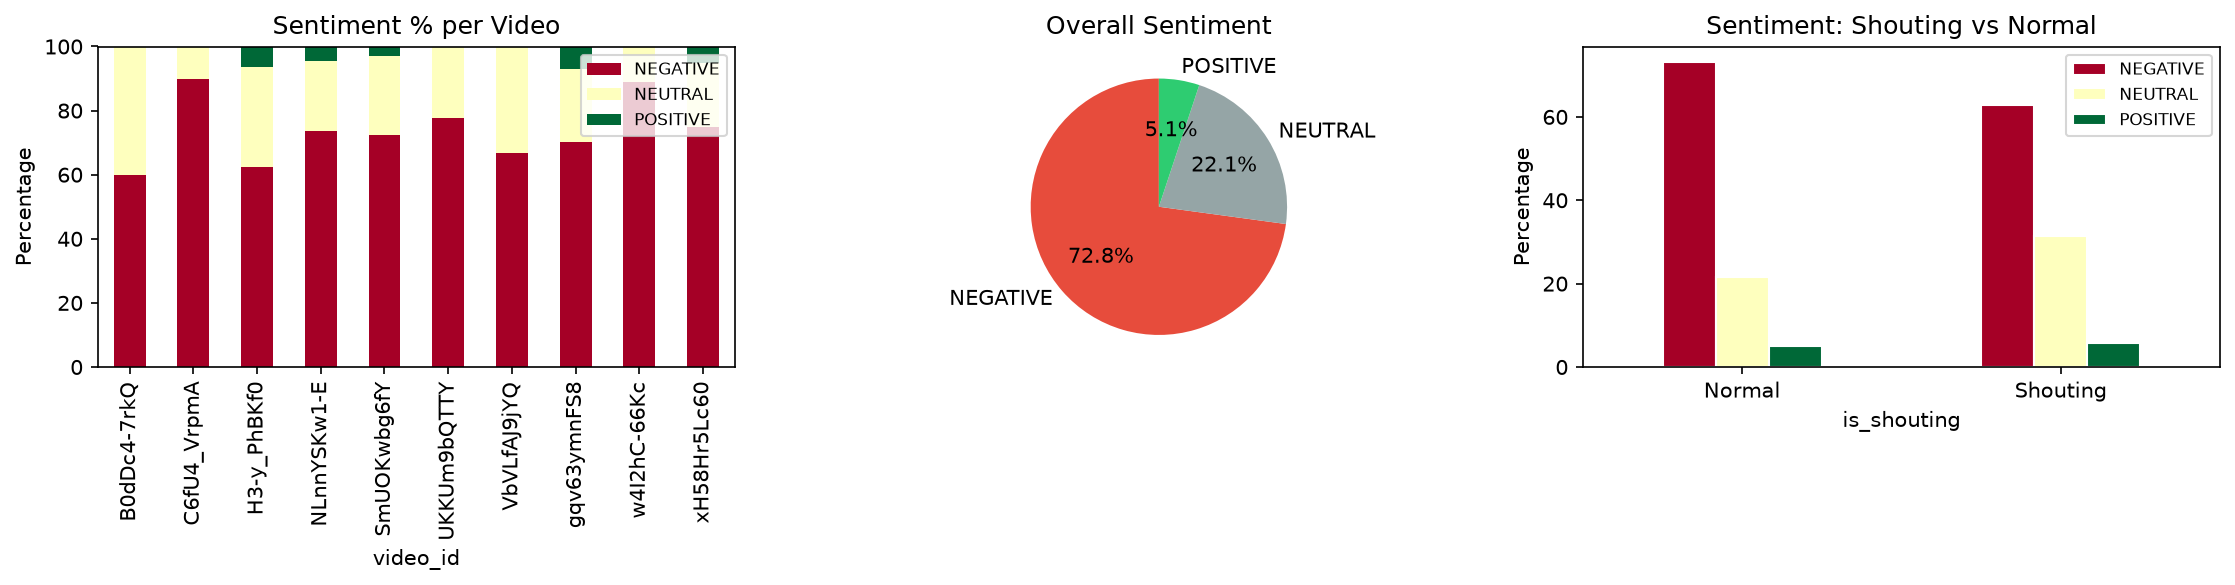

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Sentiment distribution per video (stacked bar)
videos_pivot = batch_df.groupby(["video_id", "sentiment_label"]).size().unstack(fill_value=0)
videos_pct = videos_pivot.div(videos_pivot.sum(axis=1), axis=0) * 100
videos_pct.plot(kind="bar", stacked=True, ax=axes[0], colormap="RdYlGn")
axes[0].set_title("Sentiment % per Video")
axes[0].set_ylabel("Percentage")
axes[0].legend(loc="upper right", fontsize=8)

# 2) Overall sentiment pie
overall_counts = batch_df["sentiment_label"].value_counts()
colors = {"POSITIVE": "#2ecc71", "NEGATIVE": "#e74c3c", "NEUTRAL": "#95a5a6"}
axes[1].pie(
    overall_counts.values,
    labels=overall_counts.index,
    autopct="%1.1f%%",
    colors=[colors.get(l, "#999") for l in overall_counts.index],
    startangle=90,
)
axes[1].set_title("Overall Sentiment")

# 3) Shouting vs normal contrast
shouting_plot = batch_df.groupby("is_shouting")["sentiment_label"].value_counts(normalize=True).mul(100).unstack()
shouting_plot.plot(kind="bar", ax=axes[2], colormap="RdYlGn", edgecolor="white")
axes[2].set_title("Sentiment: Shouting vs Normal")
axes[2].set_ylabel("Percentage")
axes[2].set_xticklabels(["Normal", "Shouting"], rotation=0)
axes[2].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

## Export
Save the scored batch with sentiment labels and confidence scores
for downstream analysis or comparison across batches.

In [29]:
output_dir = "../output"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, f"scored_{BATCH_NAME}")
batch_df.to_csv(output_path, index=False)
print(f"Exported {len(batch_df)} scored comments to {output_path}")

Exported 3392 scored comments to ../output/scored_youtube_comments_batch_1.csv


### Aggregation Method: Most Confident Sentence

To produce one label per comment from multiple sentences, we compared two strategies:

- **Majority Vote** — assign the most frequent label across sentences
- **Most Confident** — assign the label of the highest-confidence sentence

**Chosen: Most Confident** — crisis comments often have one emotionally intense
sentence (grief, anger, blame) surrounded by filler. The most confident sentence
captures the dominant tone, while majority voting dilutes the signal.

**Note**: May slightly bias NEGATIVE (negative emotions get higher confidence
scores), which is acceptable for detecting crisis distress signals.

In [30]:
# Most confident (already in batch_df)
most_confident = best[['sentiment_label', 'sentiment_score']]
most_confident.columns = ['mc_label', 'mc_score']

# Majority vote for comparison
majority = df_sentences.groupby('comment_idx')['sentiment_label'].agg(
    lambda x: x.mode().iloc[0]
).to_frame('mv_label')

# Compare
comparison = most_confident.join(majority)
comparison['match'] = comparison['mc_label'] == comparison['mv_label']
print(f"Agreement rate between methods: {comparison['match'].mean():.1%}")

disagreements = comparison[~comparison['match']]
print(f"Disagreements: {len(disagreements)} of {len(comparison)} comments")
if len(disagreements) > 0:
    print("\nSample disagreements (Most Confident → Majority):")
    for idx in disagreements.index[:5]:
        row = disagreements.loc[idx]
        print(f"  [{row['mc_label']} ({row['mc_score']:.2f}) vs {row['mv_label']}]")

Agreement rate between methods: 95.0%
Disagreements: 171 of 3392 comments

Sample disagreements (Most Confident → Majority):
  [NEUTRAL (0.86) vs NEGATIVE]
  [NEUTRAL (0.63) vs NEGATIVE]
  [NEUTRAL (0.46) vs NEGATIVE]
  [NEGATIVE (0.82) vs NEUTRAL]
  [POSITIVE (0.78) vs NEGATIVE]
